# BUS-BRA: classification under lesion-boundary uncertainty (submission notebook)

Mostafa Bdeir and Hadi Fardan. This notebook walks through the whole workflow: data audit and patient splits, feature extraction, the Logistic Regression and RBF SVM baselines with nested tuning, the boundary-edit stress tests, stability feature selection, patient-level calibration, the saved held-out results, failure analysis, complexity analysis and loading the trained model.

**Three run modes** (set `RUN_MODE` in the next cell):

| Mode | What it does | Needs | Time |
|---|---|---|---|
| `saved` (default) | Shows the saved result tables, recomputes held-out metrics from saved patient probabilities, verifies and loads the trained model | This repository only | seconds |
| `derived` | Also retrains everything from the saved derived feature files (`derived_features/`): baselines, stress tests, stability selection, calibration | This repository only | about 3 minutes |
| `full` | Starts from the raw archive: audits it, extracts features and perturbed features, then runs every stage | `data/raw/BUSBRA.zip` ([Zenodo](https://zenodo.org/records/8231412)) | about 8 minutes |

**Held-out safety.** No mode runs the locked held-out evaluation (`src.heldout_evaluation`) or the final-report script. The held-out numbers here are recomputed from the saved patient probabilities only, and the notebook asserts this at the end. The development stages write to a temporary working copy, never to the repository.

## 1. Setup

In [1]:
import os, sys, json, hashlib, shutil, subprocess, inspect, time
from pathlib import Path
from importlib.metadata import version
from tempfile import mkdtemp
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
from sklearn.metrics import balanced_accuracy_score, roc_auc_score, brier_score_loss, log_loss, confusion_matrix

RUN_MODE = "full"          # "saved" | "derived" | "full"   <-- change this to retrain
RUN_BENCHMARK = False       # development-only timing benchmark (about 1 minute); needs RUN_MODE != "saved"

# Locate the repository root (the folder that contains src/features.py)
here = Path.cwd().resolve()
root = Path(os.environ.get("BUS_BRA_ROOT", next((p for p in (here, *here.parents) if (p / "src/features.py").is_file()), here))).resolve()
sys.path.insert(0, str(root))
tables = root / "reports/submission_v2/tables"
published = root / "reports/final_step22_run2"
derived = root / "derived_features"
archive = root / "data/raw/BUSBRA.zip"
assert RUN_MODE in ("saved", "derived", "full")
if RUN_MODE == "full" and not archive.is_file():
    raise FileNotFoundError(f"RUN_MODE='full' needs {archive} (download BUSBRA.zip from https://zenodo.org/records/8231412)")

pinned = {"numpy": "2.5.4", "pandas": "3.0.6", "scikit-learn": "1.9.1", "scipy": "1.18.1", "scikit-image": "0.26.0", "joblib": "1.6.0"}
installed = {p: version(p) for p in pinned}
print("Python", sys.version.split()[0], "| mode:", RUN_MODE)
for p, v in pinned.items():
    print(f"  {p:14s} installed {installed[p]:8s} pinned {v}", "" if installed[p] == v else "  <-- differs from the original run")

def show_table(name):
    "Display a saved result table from reports/submission_v2/tables."
    df = pd.read_csv(tables / name)
    display(df)
    return df

Python 3.14.6 | mode: full
  numpy          installed 2.5.4    pinned 2.5.4 
  pandas         installed 3.0.6    pinned 3.0.6 
  scikit-learn   installed 1.9.1    pinned 1.9.1 
  scipy          installed 1.18.1   pinned 1.18.1 
  scikit-image   installed 0.26.0   pinned 0.26.0 
  joblib         installed 1.6.0    pinned 1.6.0 


## 2. Data audit and patient-level splits

Every split is by **patient**, never by image, because a patient can have several views. The committed split files are locked: `src.splits` refuses to overwrite them if the dataset disagrees. Development = 851 patients (1,514 images) with five locked outer folds; test = 213 patients (361 images), untouched until the one-shot evaluation.

In [2]:
images = pd.read_csv(root / "splits/image_splits.csv")
patients = pd.read_csv(root / "splits/patient_splits.csv")

# Integrity checks: unique IDs, one split and one fold per patient, no patient in both development and test
assert images.ID.is_unique and patients.Case.is_unique
assert images.groupby("Case").split.nunique().max() == 1
assert images.groupby("Case").dev_fold.nunique().max() == 1
assert set(patients.loc[patients.split == "development", "Case"]).isdisjoint(patients.loc[patients.split == "test", "Case"])
display(patients.groupby(["split", "Pathology"]).agg(patients=("Case", "size"), images=("n_images", "sum")))
print("Development patients per outer fold:\n", patients[patients.split == "development"].groupby("dev_fold").size().to_string())

if RUN_MODE == "full":
    # Audit the raw archive and verify the locked splits against it (writes into a temp copy, not the repo)
    print("Archive audit and split verification run in the working copy below.")

patients  images
split       Pathology                  
development benign          577    1023
            malignant       274     491
test        benign          145     245
            malignant        68     116

Development patients per outer fold:
 dev_fold
0    171
1    170
2    170
3    170
4    170
Archive audit and split verification run in the working copy below.


## 3. Working copy for the development stages

The stages below run as separate processes (`python -m src.<module>`) in a temporary copy of `src/` and `splits/`, so the repository is never modified. In `derived` mode the saved derived feature files are copied in; in `full` mode the raw archive is copied in and the extraction stages run first.

In [3]:
work = None
def run(module, *args):
    "Run one pipeline stage in the working copy and print the tail of its output."
    assert module not in ("src.heldout_evaluation", "src.final_report"), "held-out stages are never run here"
    t0 = time.time()
    proc = subprocess.run([sys.executable, "-m", module, *args], cwd=work, capture_output=True, text=True)
    tail = "\n".join(proc.stdout.strip().splitlines()[-4:])
    print(f"[{module} {' '.join(args)}] {time.time()-t0:.0f}s exit={proc.returncode}\n{tail}\n")
    if proc.returncode:
        print(proc.stderr[-1500:])
        raise RuntimeError(f"{module} failed")

if RUN_MODE != "saved":
    work = Path(mkdtemp(prefix="busbra-work-"))
    shutil.copytree(root / "src", work / "src", ignore=shutil.ignore_patterns("__pycache__"))
    shutil.copytree(root / "splits", work / "splits")
    (work / "data/processed").mkdir(parents=True)
    (work / "results/robustness").mkdir(parents=True)
    print("Working copy:", work)
    if RUN_MODE == "full":
        (work / "data/raw").mkdir(parents=True)
        shutil.copy2(archive, work / "data/raw/BUSBRA.zip")
        run("src.data")
        run("src.splits")                                   # verifies the locked split files against the archive
        run("src.features", "--all-development")            # 23 clean features per development image
        run("src.perturbations", "--all-development")       # original eight-condition masks (geometry audit)
        run("src.perturbed_features", "--all-development")  # features for those masks
        run("src.coherent_perturbations", "--all-development")
        run("src.coherent_features", "--all-development")
    else:
        for name in ("development_features.csv", "development_perturbed_features.csv", "development_coherent_features.csv"):
            shutil.copy2(derived / name, work / "data/processed" / name)
        shutil.copy2(derived / "coherent_geometry_development.csv", work / "results/robustness/coherent_geometry_development.csv")
        print("Derived feature files copied in; extraction stages are skipped.")
else:
    print("RUN_MODE='saved': stages are not run; saved tables are shown instead.")

Working copy: C:\Users\<user>\AppData\Local\Temp\busbra-work-7gvh5hp_


[src.data ] 4s exit=0
5-fold-cv.csv: split patients=0, missing IDs=0
10-fold-cv.csv: split patients=0, missing IDs=0
Blocking issues: 0
Report: C:\Users\<user>\AppData\Local\Temp\busbra-work-7gvh5hp_\results\audit\summary.json



[src.splits ] 1s exit=0
Dev fold 4: 170 validation patients (benign 115, malignant 55)
Patient leakage: 0
Fold overlap: 0
Split files: C:\Users\<user>\AppData\Local\Temp\busbra-work-7gvh5hp_\splits



[src.features --all-development] 8s exit=0
Extracted 1500/1514 development images...
Extracted 1514 development images
Computed 23 features per image
Saved: C:\Users\<user>\AppData\Local\Temp\busbra-work-7gvh5hp_\data\processed\development_features.csv



[src.perturbations --all-development] 46s exit=0
shift_up_moderate      1514       0.902    0.806    0.980
shift_down_moderate    1514       0.901    0.806    0.932
Saved: C:\Users\<user>\AppData\Local\Temp\busbra-work-7gvh5hp_\results\robustness\perturbation_geometry_development.csv
These are geometry checks, not classifier robustness results.



[src.perturbed_features --all-development] 80s exit=0
Step 12 geometry report: MATCHED
Test set: NOT USED
Saved feature table: C:\Users\<user>\AppData\Local\Temp\busbra-work-7gvh5hp_\data\processed\development_perturbed_features.csv
Saved summary: C:\Users\<user>\AppData\Local\Temp\busbra-work-7gvh5hp_\results\robustness\perturbed_feature_summary.json



[src.coherent_perturbations --all-development] 43s exit=0
erosion_moderate    1514        0.90                    0.0340                    0.0352
dilation_moderate   1514        0.90                    0.0270                    0.0350
Geometry-only; NO model training/predictions; original Step 14 results preserved.
Saved: C:\Users\<user>\AppData\Local\Temp\busbra-work-7gvh5hp_\results\robustness\coherent_geometry_development.csv



[src.coherent_features --all-development] 38s exit=0
Cached clean features and Step 14.3 geometry: MATCHED
Original Step 14 robustness results: UNCHANGED
Held-out test: NOT USED
Saved: C:\Users\<user>\AppData\Local\Temp\busbra-work-7gvh5hp_\data\processed\development_coherent_features.csv



## 4. Features and the two boundary-edit constructions

Each image and its lesion mask give 23 handcrafted features: six shape, seven intensity and ten masked texture features. The figure compares the **original** edit construction (boundary pixels chosen by distance to the contour, pseudo-random tie-break, which can scatter isolated pixel changes) with the **coherent** construction (one connected patch near a contour anchor). Both target an overlap (IoU) of about 0.95 with the original mask.

Real development image: bus_0003-r
IoU original construction 0.950 | coherent construction 0.950


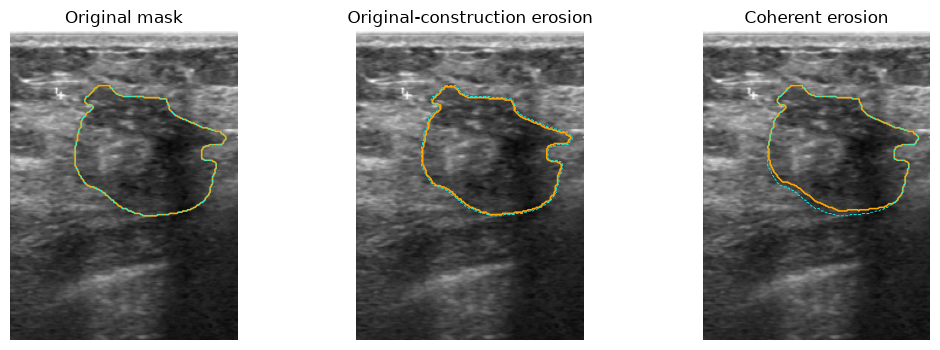

,clean,original erosion,coherent erosion,abs change (orig),abs change (coherent)
shape_area_fraction,0.1909,0.1814,0.1814,0.0095,0.0095
shape_axis_ratio,1.3230,1.3292,1.4002,0.0062,0.0772
shape_eccentricity,0.6547,0.6588,0.7000,0.0041,0.0452
shape_solidity,0.9179,0.9105,0.9118,0.0075,0.0061
shape_extent,0.6842,0.6730,0.6750,0.0112,0.0092
shape_circularity,0.7016,0.6770,0.6875,0.0247,0.0141
int_mean,0.3358,0.3343,0.3371,0.0015,0.0012
int_std,0.0941,0.0946,0.0952,0.0004,0.0011
int_median,0.3255,0.3255,0.3255,0.0000,0.0000
int_p10,0.2235,0.2196,0.2235,0.0039,0.0000


In [4]:
from src.features import read_pair, preprocess_pair, extract_features, FEATURE_COLUMNS
from src.perturbations import partial_boundary_change, mask_iou
from src.coherent_perturbations import coherent_boundary_change

if archive.is_file():
    from zipfile import ZipFile
    image_id = images.loc[images.split.eq("development"), "ID"].sort_values().iloc[3]
    with ZipFile(archive) as z:
        gray, mask = read_pair(z, image_id)
    print("Real development image:", image_id)
else:
    yy, xx = np.ogrid[:160, :200]
    mask = ((yy - 80) / 32) ** 2 + ((xx - 100) / 44) ** 2 <= 1
    gray = (120 + 40 * np.sin(xx / 7.0) + 20 * np.cos(yy / 5.0)).clip(0, 255).astype(np.uint8) * np.ones_like(yy, dtype=np.uint8)
    print("Raw archive not present: using a synthetic ellipse so the demo still runs.")
gray, mask = preprocess_pair(gray, mask)          # grayscale, longest side 256, nearest-neighbour mask
orig_erosion = partial_boundary_change(mask, 0.95, "erosion")
coh_erosion = coherent_boundary_change(mask, 0.95, "erosion")
print(f"IoU original construction {mask_iou(mask, orig_erosion):.3f} | coherent construction {mask_iou(mask, coh_erosion):.3f}")

fig, axes = plt.subplots(1, 3, figsize=(11, 3.6))
for ax, m, title in zip(axes, [mask, orig_erosion, coh_erosion], ["Original mask", "Original-construction erosion", "Coherent erosion"]):
    ax.imshow(gray, cmap="gray"); ax.contour(m, levels=[.5], colors="orange", linewidths=1.2)
    ax.contour(mask, levels=[.5], colors="cyan", linewidths=.6, linestyles="dashed"); ax.set_title(title); ax.axis("off")
plt.tight_layout(); plt.show()

demo = pd.DataFrame([extract_features(gray, mask), extract_features(gray, orig_erosion), extract_features(gray, coh_erosion)],
                    index=["clean", "original erosion", "coherent erosion"]).T
demo["abs change (orig)"] = (demo["original erosion"] - demo["clean"]).abs()
demo["abs change (coherent)"] = (demo["coherent erosion"] - demo["clean"]).abs()
display(demo.round(4))

## 5. Baselines: Logistic Regression and RBF SVM with nested tuning

Outer loop: five locked patient folds. Inner loop: three patient-stratified folds choose the hyperparameters by patient balanced accuracy (ties broken by AUC, then the simpler setting). Scaling and fitting use training folds only, and each patient contributes total weight one across their views. The next cell shows the tuning code itself.

In [5]:
import src.models as M
print(inspect.getsource(M.patient_image_weights))
print(inspect.getsource(M.choose_settings))

def patient_image_weights(df: pd.DataFrame, balance: bool = False) -> np.ndarray:
    """Make each patient contribute total weight 1 (then optional case balancing)."""
    n_per_case = df.groupby("Case")["ID"].transform("size").to_numpy(dtype=float)
    weights = 1.0 / n_per_case
    if balance:
        patients = df.groupby("Case")["Pathology"].first()
        class_counts = patients.value_counts()
        if len(class_counts) != 2:
            raise ValueError("Class weighting requires two classes")
        n_cases = len(patients)
        case_factors = {label: n_cases / (2.0 * int(count)) for label, count in class_counts.items()}
        weights *= df["Pathology"].map(case_factors).to_numpy(dtype=float)
    return weights

def choose_settings(train: pd.DataFrame, *, seed: int = SEED,
                    cs=CS, balances=BALANCE_OPTIONS,
                    n_splits: int = NUM_INNER_FOLDS) -> dict:
    """Choose hyperparameters by inner-fold patient BA (not outer test fold)."""
    in

In [6]:
if RUN_MODE != "saved":
    run("src.models")      # Logistic Regression: nested CV, C in {0.01..100}, class balancing off/on
    run("src.svm_model")   # RBF SVM: nested CV, C in {0.1,1,10}, gamma in {scale,0.01,0.1}, balancing off/on
    base = {n: json.loads((work / f"results/modeling/{n}_nested_cv_summary.json").read_text()) for n in ("logreg", "svm")}
    print({n: {k: round(v[k], 4) for k in ("balanced_accuracy", "roc_auc")} for n, v in base.items()})
else:
    print("Saved result: LR BA 86.89% / AUC 0.9304 ; SVM BA 87.07% / AUC 0.9352 (development, original clean baselines)")
print("Hyperparameters chosen in each outer fold (saved table):")
_ = show_table("table_chosen_hyperparameters.csv")

[src.models ] 4s exit=0
Outer fold 4: 170 patients | C=1, balanced=True | BA=0.889, AUC=0.911, FN=6
Overall OOF BA=0.8689, sensitivity=0.8504, specificity=0.8873, AUC=0.9304, FN=41
Saved evaluation results: C:\Users\<user>\AppData\Local\Temp\busbra-work-7gvh5hp_\results\modeling
Saved provisional development-only model: C:\Users\<user>\AppData\Local\Temp\busbra-work-7gvh5hp_\models\logreg_development_candidate.joblib



[src.svm_model ] 9s exit=0
Outer fold 4: 170 patients | C=1, gamma=scale, balanced=True | BA=0.884, AUC=0.926, FN=7
Overall OOF BA=0.8707, sensitivity=0.8540, specificity=0.8873, AUC=0.9352, FN=40
Saved evaluation results: C:\Users\<user>\AppData\Local\Temp\busbra-work-7gvh5hp_\results\modeling
Saved provisional development-only model: C:\Users\<user>\AppData\Local\Temp\busbra-work-7gvh5hp_\models\svm_development_candidate.joblib

{'logreg': {'balanced_accuracy': 0.8689, 'roc_auc': 0.9304}, 'svm': {'balanced_accuracy': 0.8707, 'roc_auc': 0.9352}}
Hyperparameters chosen in each outer fold (saved table):


,Model,Outer fold,C,gamma,Class balancing,Outer-fold BA (%)
0,LR,0,100,-,on,83.5
1,LR,1,10,-,on,84.6
2,LR,2,100,-,on,88.0
3,LR,3,1,-,on,89.4
4,LR,4,1,-,on,88.9
5,SVM,0,1,scale,on,85.4
6,SVM,1,1,0.01,on,85.9
7,SVM,2,10,0.01,on,89.3
8,SVM,3,1,scale,on,86.2
9,SVM,4,1,scale,on,88.4


## 6. Boundary-sensitivity stress tests (development data, models fixed)

The trained models and thresholds stay fixed, and only the lesion mask changes. Eight conditions: mild and moderate erosion and dilation, and four shifts. Then the same erosion and dilation conditions with the coherent construction.

[src.robustness_eval ] 3s exit=0
svm    | shift_up_moderate      |      851 | +0.0021 |  1.65% |      1
svm    | shift_down_moderate    |      851 | +0.0000 |  1.65% |      4
Saved: C:\Users\<user>\AppData\Local\Temp\busbra-work-7gvh5hp_\results\robustness
Both clean reference OOF tables: MATCHED | Held-out test: NOT USED



[src.coherent_eval ] 2s exit=0
   svm      erosion_mild                851                -0.005566   0.018801                    4
   svm  erosion_moderate                851                -0.005474   0.027027                    4
Step 14 clean predictions: MATCHED | Held-out evaluation: NOT USED
Saved: C:\Users\<user>\AppData\Local\Temp\busbra-work-7gvh5hp_\results\robustness\coherent_step16

Original construction (development, paired changes vs each model's own clean baseline):


,Model,Condition,Patients,Delta BA (pp),Flip (%),New FN,Recovered FN
0,LR,Mild erosion,851,-16.77,31.6,1,24
1,LR,Mild dilation,851,-15.66,30.0,2,24
2,LR,Moderate erosion,851,-2.57,9.4,4,17
3,LR,Moderate dilation,851,-3.92,9.5,5,12
4,LR,Shift left,849,-0.78,2.0,3,3
5,LR,Shift right,841,-0.59,1.5,0,2
6,LR,Shift up,851,-0.75,3.5,2,5
7,LR,Shift down,851,-0.34,2.9,3,4
8,SVM,Mild erosion,851,-6.58,16.3,0,19
9,SVM,Mild dilation,851,-5.90,14.8,1,19


Coherent construction:


,Model,Condition,Delta BA (pp),Flip (%),New FN,Recovered FN
0,LR,Mild erosion,-0.45,2.0,4,2
1,LR,Mild dilation,-1.43,5.2,1,6
2,LR,Moderate erosion,-0.71,3.1,5,3
3,LR,Moderate dilation,-2.54,7.8,2,8
4,SVM,Mild erosion,-0.56,1.9,4,0
5,SVM,Mild dilation,0.18,3.9,1,11
6,SVM,Moderate erosion,-0.55,2.7,4,1
7,SVM,Moderate dilation,-0.98,5.4,4,10


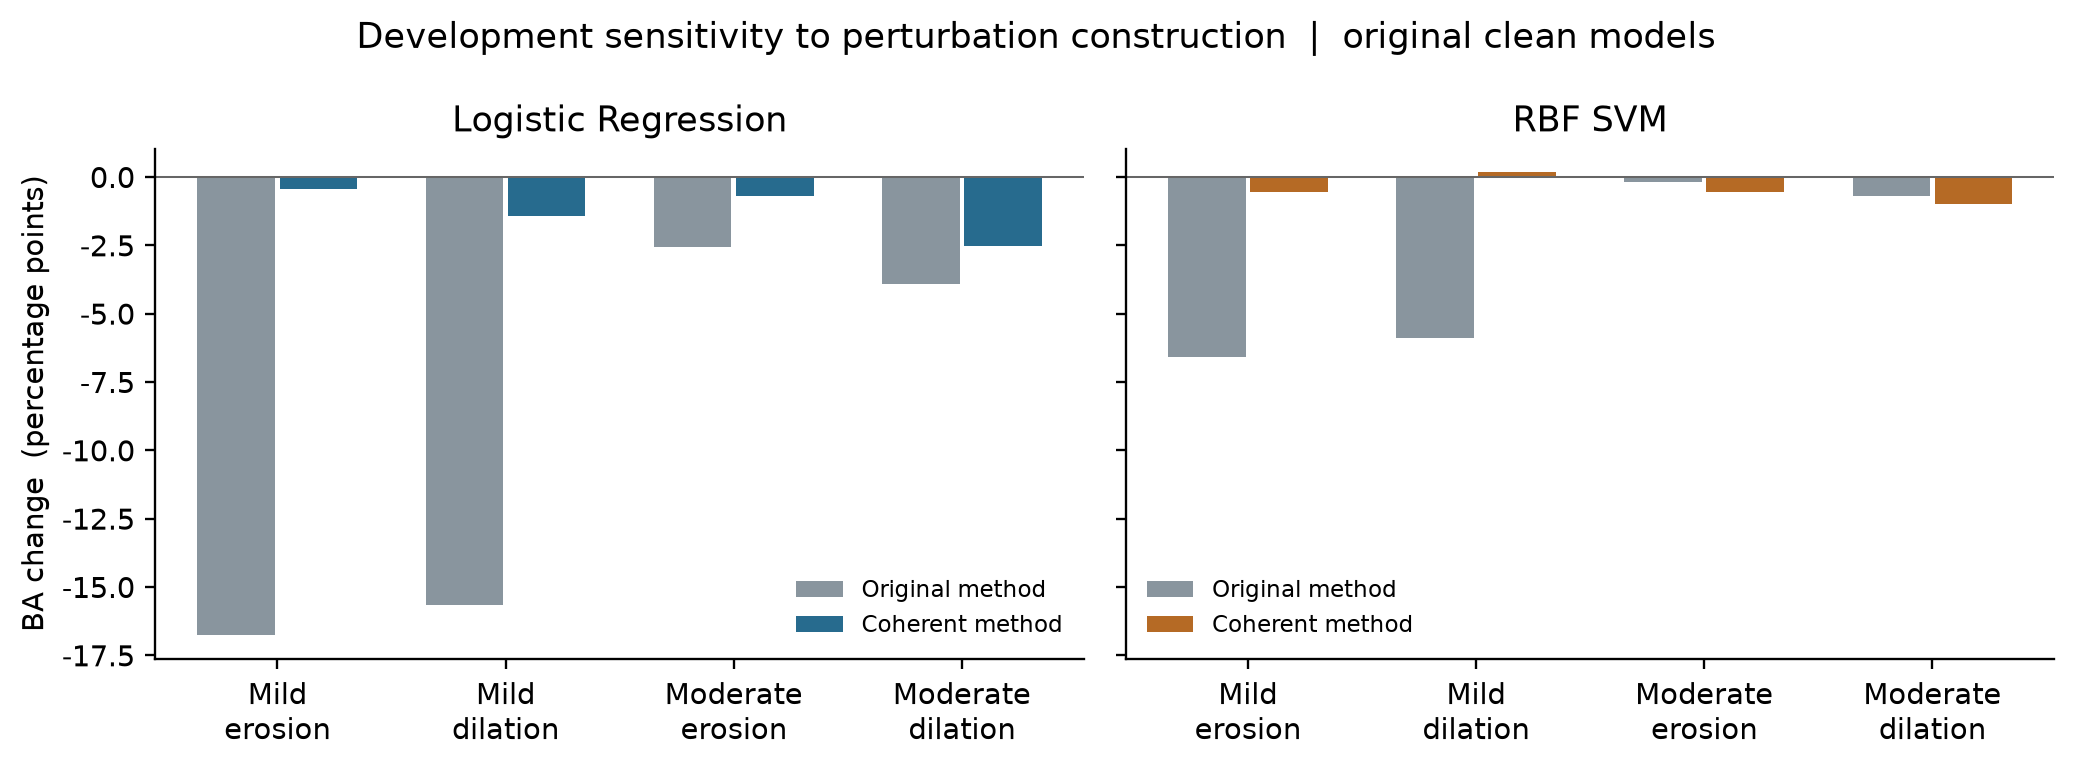

In [7]:
if RUN_MODE != "saved":
    run("src.robustness_eval")      # original construction, eight conditions
    run("src.coherent_eval")        # coherent construction, four conditions (post-hoc, labelled as such)
print("Original construction (development, paired changes vs each model's own clean baseline):")
orig = show_table("table_original_eight_conditions.csv")
print("Coherent construction:")
_ = show_table("table_coherent_development.csv")
display(Image(filename=str(root / "reports/submission_v2/figures/06_original_and_coherent.png")))

## 7. Stability feature selection (the mitigation experiment)

Inside every training partition, each feature's stability is its largest mean absolute change under the four coherent edits, divided by its clean standard deviation (lower is better). Subsets of 5, 10 and 15 features are candidates; the model grids are tuned with an objective that weights clean balanced accuracy and the four perturbed balanced accuracies equally. A matched all-23 comparator uses the same grids and objective.

In [8]:
import src.stable_selection as SS
print(inspect.getsource(SS.rank_training_features)[:2600], "\n...")

def rank_training_features(clean: pd.DataFrame, coherent: pd.DataFrame, *,
                           training_cases: set, forbidden_cases: set) -> pd.DataFrame:
    """Slice training patients FIRST: excluded feature values cannot affect fit."""
    training_cases, forbidden_cases = set(training_cases), set(forbidden_cases)
    if not training_cases or training_cases & forbidden_cases:
        raise ValueError("Empty training scope or overlap with forbidden patients")
    train = clean.loc[clean.Case.isin(training_cases)].copy()
    pert = coherent.loc[coherent.Case.isin(training_cases)].copy()
    if set(train.Case) != training_cases or set(pert.Case) != training_cases:
        raise ValueError("Missing training patients")
    if (train.ID.duplicated().any() or not train.split.eq("development").all()
            or not pert.split.eq("development").all()
            or pert.duplicated(["ID", "condition"]).any()
            or set(pert.condition) != set(COHERENT_CONDITIONS)
            

In [9]:
if RUN_MODE != "saved":
    run("src.stable_selection")     # freezes the design and audits patient-disjoint training scopes
    run("src.stable_evaluation")    # nested evaluation of the subset arm vs the matched all-23 arm
print("Matched nested development comparison (saved table):")
_ = show_table("clean_summary.csv")
print("Features selected by the stability procedure, number of outer folds (of 5):")
_ = show_table("table_stability_selection_frequency.csv")

[src.stable_selection ] 1s exit=0
Outer fold 4: outer-training scope and three inner-training scopes audited
Frozen top-k candidates: (5, 10, 15); matched all-23 comparator
Patient-disjoint scopes: 20 | Classifier fits: 0 | Held-out evaluation: NOT USED
Saved: C:\Users\<user>\AppData\Local\Temp\busbra-work-7gvh5hp_\results\robustness\selection_step18



[src.stable_evaluation ] 64s exit=0
   svm all_23_matched_tuning           0.870681     0.854015     0.887348 0.935167                0.866860
   svm        stability_topk           0.868673     0.843066     0.894281 0.934054                0.861148
Original clean OOF: MATCHED | Held-out evaluation: NOT USED
Saved: C:\Users\<user>\AppData\Local\Temp\busbra-work-7gvh5hp_\results\robustness\selection_step19

Matched nested development comparison (saved table):


,model,arm,patients,balanced_accuracy,sensitivity,specificity,roc_auc,tn,fp,fn,tp,mean_five_condition_ba
0,logreg,all_23_matched_tuning,851,0.873465,0.861314,0.885615,0.933187,511,66,38,236,0.861488
1,logreg,stability_topk,851,0.845501,0.817518,0.873484,0.928772,504,73,50,224,0.846251
2,svm,all_23_matched_tuning,851,0.870681,0.854015,0.887348,0.935167,512,65,40,234,0.866860
3,svm,stability_topk,851,0.868673,0.843066,0.894281,0.934054,516,61,43,231,0.861148


Features selected by the stability procedure, number of outer folds (of 5):


,Feature,LR folds selected (of 5),SVM folds selected (of 5)
0,glcm_asm_d1,5,5
1,glcm_asm_d3,5,5
2,glcm_contrast_d1,5,5
3,glcm_dissimilarity_d1,5,5
4,glcm_dissimilarity_d3,5,5
5,glcm_homogeneity_d1,5,5
6,glcm_homogeneity_d3,5,5
7,int_mean,5,5
8,int_median,5,5
9,int_p10,5,5


## 8. Patient-level probability calibration and the final models

Each outer training pool is split into three patient folds. For each fold, a base model is tuned on the other two folds and a sigmoid is fitted on the reserved patients' clean scores, keeping tuning, fitting and calibration patients disjoint. The three members are averaged. The decision threshold is fixed at 0.5.

In [10]:
if RUN_MODE != "saved":
    run("src.patient_calibration")   # calibrated nested CV + final development-only ensembles (no held-out access)
    for leftover in ("held_out_evaluation_started.json",):
        assert not (work / "results/robustness/calibration_step20" / leftover).exists()
print("Calibrated outer-fold development performance (saved table):")
_ = show_table("calibrated_clean_summary.csv")
print("Fold-to-fold variation (calibrated development predictions):")
_ = show_table("table_fold_variation.csv")

[src.patient_calibration ] 38s exit=0
logreg           0.841567     0.729927     0.953206 0.934832     0.091477  0.307780
   svm           0.847316     0.751825     0.942808 0.935844     0.088775  0.299981
Final protocol: FROZEN | Held-out evaluation: NOT USED
Saved: C:\Users\<user>\AppData\Local\Temp\busbra-work-7gvh5hp_\results\robustness\calibration_step20

Calibrated outer-fold development performance (saved table):


,model,patients,balanced_accuracy,sensitivity,specificity,roc_auc,tn,fp,fn,tp,brier_score,log_loss
0,logreg,851,0.841567,0.729927,0.953206,0.934832,550,27,74,200,0.091477,0.307780
1,svm,851,0.847316,0.751825,0.942808,0.935844,544,33,68,206,0.088775,0.299981


Fold-to-fold variation (calibrated development predictions):


,Model,Mean BA (%),SD across folds (pp),Min (%),Max (%)
0,LR,84.15,2.02,81.9,87.0
1,SVM,84.71,2.88,80.3,87.4


## 9. Reproduction check

When a mode that retrains is used, the rebuilt numbers must equal the published development numbers. In `saved` mode the same constants are checked against the saved tables.

In [11]:
published_numbers = {
    "LR baseline BA": 0.8689, "SVM baseline BA": 0.8707,
    "LR all-23 clean BA": 0.8735, "LR subset clean BA": 0.8455, "SVM all-23 clean BA": 0.8707, "SVM subset clean BA": 0.8687,
    "LR calibrated BA": 0.8416, "SVM calibrated BA": 0.8473,
}
src_dir = work / "results/robustness" if work else None
def tbl(path_work, path_saved):
    return pd.read_csv((src_dir / path_work) if work else (tables / path_saved))
cs = tbl("selection_step19/clean_summary.csv", "clean_summary.csv")
cal = tbl("calibration_step20/calibrated_clean_summary.csv", "calibrated_clean_summary.csv")
get = lambda df, m, arm=None: float(df[(df.model == m) & ((df.arm == arm) if arm else True)].balanced_accuracy.iloc[0])
observed = {
    # In retraining modes the baseline comes from the run just made; in saved mode from the saved summaries
    "LR baseline BA": base["logreg"]["balanced_accuracy"] if work else float(json.loads((tables / "baseline_summary_logreg.json").read_text())["balanced_accuracy"]),
    "SVM baseline BA": base["svm"]["balanced_accuracy"] if work else float(json.loads((tables / "baseline_summary_svm.json").read_text())["balanced_accuracy"]),
    "LR all-23 clean BA": get(cs, "logreg", "all_23_matched_tuning"), "LR subset clean BA": get(cs, "logreg", "stability_topk"),
    "SVM all-23 clean BA": get(cs, "svm", "all_23_matched_tuning"), "SVM subset clean BA": get(cs, "svm", "stability_topk"),
    "LR calibrated BA": get(cal, "logreg"), "SVM calibrated BA": get(cal, "svm"),
}
check = pd.DataFrame({"published": published_numbers, "observed": {k: round(v, 4) for k, v in observed.items()}})
check["match"] = (check.published - check.observed).abs() < 5e-4
display(check)
assert check.match.all(), "a development number does not match the published one"
print("All development numbers match the published ones.")

,published,observed,match
LR baseline BA,0.8689,0.8689,True
SVM baseline BA,0.8707,0.8707,True
LR all-23 clean BA,0.8735,0.8735,True
LR subset clean BA,0.8455,0.8455,True
SVM all-23 clean BA,0.8707,0.8707,True
SVM subset clean BA,0.8687,0.8687,True
LR calibrated BA,0.8416,0.8416,True
SVM calibrated BA,0.8473,0.8473,True


All development numbers match the published ones.


## 10. Locked held-out results, recomputed from saved patient probabilities

The one-shot held-out evaluation was run once during the study with frozen models. Here nothing is refitted or re-predicted: the metrics are recomputed from the saved per-patient probabilities (`patient_failure_audit.csv`), and the paired comparison counts patients.

In [12]:
audit = pd.read_csv(published / "patient_failure_audit.csv")
rows = []
for name in ("lr", "svm"):
    y, p = audit.actual, audit[f"{name}_probability"]
    tn, fp, fn, tp = confusion_matrix(y, p >= .5).ravel()
    rows.append({"model": name.upper(), "BA %": 100 * balanced_accuracy_score(y, p >= .5), "sensitivity %": 100 * tp / (tp + fn),
                 "specificity %": 100 * tn / (tn + fp), "AUC": roc_auc_score(y, p), "Brier": brier_score_loss(y, p),
                 "log loss": log_loss(y, p), "FN": fn, "FP": fp})
display(pd.DataFrame(rows).round(4))
both = int((audit.lr_error & audit.svm_error).sum()); lr_only = int((audit.lr_error & ~audit.svm_error).sum())
svm_only = int((~audit.lr_error & audit.svm_error).sum()); neither = int((~audit.lr_error & ~audit.svm_error).sum())
print(f"misclassified by both {both} | LR only {lr_only} | SVM only {svm_only} | correct for both {neither} | patients {len(audit)}")
assert (both, lr_only, svm_only, neither) == (30, 3, 0, 180)
print("Held-out coherent boundary sensitivity (saved condition table):")
display(pd.read_csv(published / "heldout_robustness_table.csv")[["model", "condition", "delta_balanced_accuracy", "flip_rate", "new_false_negatives", "recovered_false_negatives", "delta_roc_auc"]].round(4))

,model,BA %,sensitivity %,specificity %,AUC,Brier,log loss,FN,FP
0,LR,80.4209,69.1176,91.7241,0.9177,0.1024,0.3296,21,12
1,SVM,81.8458,70.5882,93.1034,0.9142,0.1030,0.3397,20,10


misclassified by both 30 | LR only 3 | SVM only 0 | correct for both 180 | patients 213
Held-out coherent boundary sensitivity (saved condition table):


,model,condition,delta_balanced_accuracy,flip_rate,new_false_negatives,recovered_false_negatives,delta_roc_auc
0,logreg,dilation_mild,0.0078,0.0188,0,2,-0.0068
1,logreg,dilation_moderate,0.0225,0.0376,0,4,-0.0111
2,logreg,erosion_mild,0.0074,0.0047,0,1,0.0039
3,logreg,erosion_moderate,0.0000,0.0188,2,2,-0.0013
4,svm,dilation_mild,0.0195,0.0469,0,5,-0.0043
5,svm,dilation_moderate,0.0117,0.0376,0,3,-0.0064
6,svm,erosion_mild,0.0005,0.0141,0,1,0.0022
7,svm,erosion_moderate,0.0039,0.0094,0,1,-0.0044


## 11. Failure analysis and complexity analysis (development data)

Errors by lesion size (tertiles of the mean area fraction of a patient's images) and by number of views, from calibrated out-of-fold predictions; and a timing comparison of one tuned LR fit against one tuned SVM fit on a development fold, with no tuning inside the timing.

In [13]:
fb = pd.read_csv(tables / "table_failure_breakdown.csv")
display(fb.pivot_table(index=["Model", "Class", "Factor"], columns="Group", values="Error rate (%)", aggfunc="first"))
print("Complexity (single development fold; comparable single-model operations, not the three-member ensembles):")
_ = show_table("table_complexity.csv")
if RUN_BENCHMARK and RUN_MODE != "saved":
    shutil.copytree(root / "analysis", work / "analysis", dirs_exist_ok=True)
    proc = subprocess.run([sys.executable, "-m", "analysis.development_analysis", "--root", str(work), "--repeats", "10"],
                          cwd=work, capture_output=True, text=True)
    print(proc.stdout[-2500:] or proc.stderr[-1500:])

Group                                 1     2  large  middle  small
Model Class     Factor                                             
LR    Benign    Lesion size         NaN   NaN   11.5     3.6    2.0
                Views per patient   3.8   4.9    NaN     NaN    NaN
      Malignant Lesion size         NaN   NaN   24.2    26.4   43.3
                Views per patient  31.6  25.8    NaN     NaN    NaN
SVM   Benign    Lesion size         NaN   NaN   12.2     5.7    2.4
                Views per patient   3.1   6.5    NaN     NaN    NaN
      Malignant Lesion size         NaN   NaN   22.2    24.2   40.0
                Views per patient  31.6  23.0    NaN     NaN    NaN

Complexity (single development fold; comparable single-model operations, not the three-member ensembles):


,Model,"Fit, no tuning (ms, median [IQR])",Predict one patient (ms),Compressed model (KB),Tuning candidates
0,LR,28.4 [27.9-29.1],2.43 [2.42-2.45],1.5,10
1,SVM,12.9 [12.8-13.0],2.56 [2.55-2.57],91.6,18


## 12. The trained model

`models/frozen_calibrated_models.joblib` holds the final three-member calibrated LR and SVM ensembles. The cell verifies its bytes and the library versions against the recorded protocol *before* deserialising it, then predicts for one **development** patient. (No test patients are used.)

In [14]:
import joblib
from src.patient_calibration import predict_ensemble
from src.models import load_development

model_path = root / "models/frozen_calibrated_models.joblib"
protocol = json.loads((root / "models/final_evaluation_protocol.json").read_text())
summary = json.loads((root / "models/calibration_summary.json").read_text())
expected = "627ef9df92e4b12b475a12c844b53e82e9dd7fefe05a9f07c3b94ca7c77f3586"   # digest recorded in the original report manifest
with model_path.open("rb") as f:
    actual = hashlib.file_digest(f, "sha256").hexdigest()
assert actual == expected == protocol["model_artifact_sha256"], "model checksum mismatch"
print("SHA-256 matches the original frozen model:", actual)
mismatch = {p: (version(p), v) for p, v in summary["versions"].items() if version(p) != v}
print("Library versions differ from the recorded ones:", mismatch or "none")
if mismatch:
    print("(Loading may still work; install the pinned requirements to match exactly.)")

bundle = joblib.load(model_path)
dev = load_development(derived / "development_features.csv", root / "splits/image_splits.csv")
sample = dev.loc[dev.Case.eq(dev.Case.iloc[0])]
print("Development patient", int(sample.Case.iloc[0]), "| true label:", sample.Pathology.iloc[0], "| views:", len(sample))
for name, ensemble in bundle["models"].items():
    print(name, [m["settings"] for m in ensemble["members"]])
    display(predict_ensemble(ensemble, sample)[["actual", "n_images", "prob_malignant", "predicted"]])

SHA-256 matches the original frozen model: 627ef9df92e4b12b475a12c844b53e82e9dd7fefe05a9f07c3b94ca7c77f3586
Library versions differ from the recorded ones: none
Development patient 2 | true label: benign | views: 2
logreg [{'C': 0.1, 'balance': True}, {'C': 10.0, 'balance': False}, {'C': 0.1, 'balance': True}]


,actual,n_images,prob_malignant,predicted
0,0,2,0.051927,0


svm [{'C': 1.0, 'balance': True, 'gamma': 'scale'}, {'C': 10.0, 'balance': True, 'gamma': 0.01}, {'C': 1.0, 'balance': True, 'gamma': 0.01}]


,actual,n_images,prob_malignant,predicted
0,0,2,0.03827,0


## 13. Safety check and summary

The notebook never ran the locked held-out evaluation. Summary of what it showed:

- Both baselines and every later development stage reproduce the published development numbers exactly.
- On the 213 held-out patients the calibrated SVM reached balanced accuracy 81.85% against 80.42% for LR; the paired difference is small (interval reaches zero), LR has the better AUC and probability losses, and the SVM missed 20 of 68 malignant patients at the fixed 0.5 threshold.
- Under the original boundary-edit construction the SVM lost less accuracy than LR; under the coherent construction both lost little; stability selection did not help.

In [15]:
# run() refuses the held-out modules; also confirm no held-out marker or output exists in the working copy
if work:
    assert not list(work.rglob("held_out_evaluation_started.json")), "a held-out marker was created"
    assert not (work / "results/robustness/heldout_step21").exists(), "held-out outputs exist"
print("No held-out stage was run. Mode used:", RUN_MODE)

No held-out stage was run. Mode used: full
